# Notebook 5 · Question 6: ablation study and McNemar's test
Runs `src/ablation_mcnemar_q6.py`. Each ablation changes one component with the split, seed and protocol fixed; McNemar's test compares the champion and the MLP on the same 2023 municipalities.

In [1]:
import sys, json, logging, warnings
from pathlib import Path
import numpy as np
import pandas as pd
from IPython.display import Image, Markdown, display

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
warnings.filterwarnings("ignore")
logging.disable(logging.WARNING)
pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 180)
pd.set_option("display.float_format", "{:.3f}".format)
RESULTS, FIGS = ROOT / "results", ROOT / "reports" / "figures"
show = lambda name, width=800: display(Image(filename=str(FIGS / name), width=width))

In [2]:
import ablation_mcnemar_q6
ablation_mcnemar_q6.main()

=== Q6.1 Ablations (fit 2018-2021, evaluate 2022 + walk-forward CV) ===


Full tuned champion (reference)                            val macro-F1=0.8867  ROC-AUC=0.9190  recall(at_risk)=0.8738  CV=0.8743


A1: remove audit-history feature (prior_audit_outcome)     val macro-F1=0.6921  ROC-AUC=0.7477  recall(at_risk)=0.6796  CV=0.6470


A2: remove financial-ratio feature group (9 ratios)        val macro-F1=0.8867  ROC-AUC=0.8872  recall(at_risk)=0.8738  CV=0.8728


A3: remove imbalance treatment (no class weighting)        val macro-F1=0.8867  ROC-AUC=0.9192  recall(at_risk)=0.8738  CV=0.8743


A4: remove scaling step (raw rand-scale values)            val macro-F1=0.6267  ROC-AUC=0.6816  recall(at_risk)=0.7087  CV=0.6477


A5: swap L1 regulariser for L2                             val macro-F1=0.8867  ROC-AUC=0.9269  recall(at_risk)=0.8738  CV=0.8713



=== Q6.2 McNemar (fit 2018-2022, same 2023 municipalities) ===


Both correct=217  Champion only=1  Comparator only=0  Both wrong=22
exact binomial (b + c < 25): statistic=0.0000  p=1.0000  reject H0 at 0.05: False
Champion acc=0.9083 macro-F1=0.9060 | MLP acc=0.9042 macro-F1=0.9016


## 6.1 Controlled ablations

,val_macro_f1,delta_val_macro_f1,val_roc_auc,delta_val_roc_auc,val_recall_at_risk,cv_macro_f1_mean
experiment,,,,,,
Full tuned champion (reference),0.887,0.000,0.919,0.000,0.874,0.874
A1: remove audit-history feature (prior_audit_outcome),0.692,-0.195,0.748,-0.171,0.680,0.647
A2: remove financial-ratio feature group (9 ratios),0.887,0.000,0.887,-0.032,0.874,0.873
A3: remove imbalance treatment (no class weighting),0.887,0.000,0.919,0.000,0.874,0.874
A4: remove scaling step (raw rand-scale values),0.627,-0.260,0.682,-0.237,0.709,0.648
A5: swap L1 regulariser for L2,0.887,0.000,0.927,0.008,0.874,0.871


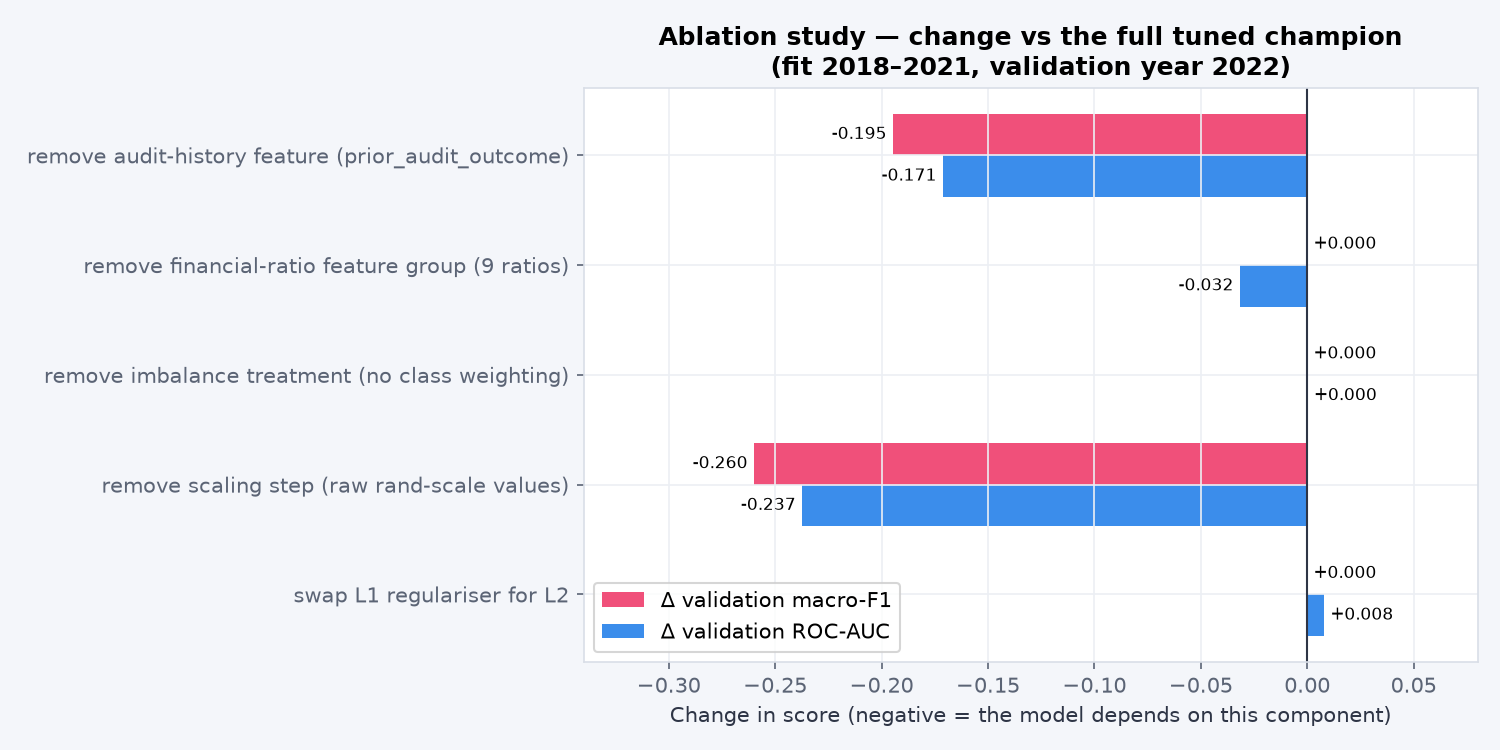

In [3]:
abl = pd.read_csv(RESULTS / "q6_ablation.csv").set_index("experiment")
display(abl[["val_macro_f1", "delta_val_macro_f1", "val_roc_auc", "delta_val_roc_auc", "val_recall_at_risk", "cv_macro_f1_mean"]])
show("q6_ablation.png", 760)

## 6.2 McNemar's test (H₀: equal error rates; α = 0.05; exact binomial when b + c < 25)

,MLP correct,MLP wrong
champion correct,217,1
champion wrong,0,22


exact binomial (b + c < 25) | statistic = 0.0 | p = 1.0 | reject H0: False


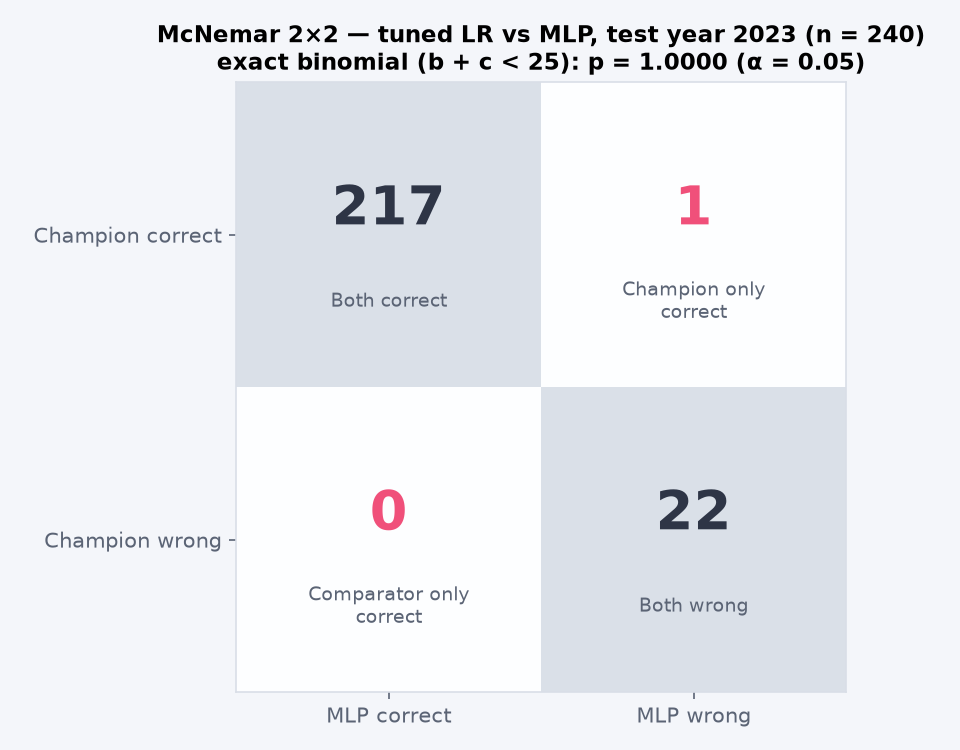

In [4]:
mc = json.loads((RESULTS / "q6_mcnemar.json").read_text())
t = mc["table"]
display(pd.DataFrame([[t["both_correct"], t["champion_only_correct"]], [t["comparator_only_correct"], t["both_wrong"]]],
                     index=["champion correct", "champion wrong"], columns=["MLP correct", "MLP wrong"]))
print(mc["test_version"], "| statistic =", mc["statistic"], "| p =", round(mc["p_value"], 4), "| reject H0:", mc["reject_H0"])
show("q6_mcnemar_table.png", 480)